# IS403 — Walmart M5: Three Forecasting Baselines

Compare Naive, Seasonal Naive (7 days), and Moving Average on the audited daily
Level 1 series. All forecasts cover **28 days from one fixed origin**. Only
`train.csv` and `val.csv` are read; test labels are not opened.

Run all cells on Kaggle CPU with the same processed dataset as notebook 00.
Leave the path overrides as `None` for automatic input discovery. No package
installation or Internet connection is required.

The three development windows are consecutive 28-day blocks before Test. The
last window is the designated Validation set. These three nearby windows do
not represent every season of the year, and their scores are development
scores, not an independent final test result.

In [1]:
from pathlib import Path
from importlib import metadata
from datetime import datetime, timezone
from time import perf_counter
from zipfile import ZipFile, ZIP_DEFLATED
import hashlib
import json
import platform
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = None
OUTPUT_DIR = None

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

HORIZON = 28
SEASON_LENGTH = 7
MA_WINDOWS = (7, 28)
ORIGINS = (1829, 1857, 1885)
RUN_STARTED = perf_counter()

## 1. Load the audited development data

Fingerprints check every value in the two development CSV files. The original
14-column schema and chronological split are preserved. Categorical event
labels are retained but are not inputs to these history-only baselines.

In [2]:
FILENAMES = ('train.csv', 'val.csv')


def find_data_directory(override=None):
    if override is not None:
        selected = Path(override).expanduser().resolve()
        if not all((selected / name).is_file() for name in FILENAMES):
            raise FileNotFoundError(f'Expected train.csv and val.csv in: {selected}')
        return selected

    candidates = set()
    for directory in [Path.cwd(), Path.cwd() / 'dataset',
                      Path.cwd() / '02_Data' / 'processed']:
        if all((directory / name).is_file() for name in FILENAMES):
            candidates.add(directory.resolve())

    root = Path('/kaggle/input')
    if root.is_dir():
        for path in root.rglob('train.csv'):
            if all((path.parent / name).is_file() for name in FILENAMES):
                candidates.add(path.parent.resolve())

    if not candidates:
        raise FileNotFoundError(
            'Attach the processed Kaggle dataset containing train.csv and val.csv, '
            'or set DATA_DIR explicitly.'
        )
    if len(candidates) > 1:
        options = '\n'.join(str(path) for path in sorted(candidates))
        raise ValueError(f'Multiple datasets found. Set DATA_DIR explicitly:\n{options}')
    return candidates.pop()


data_dir = find_data_directory(DATA_DIR)
output_dir = Path(OUTPUT_DIR) if OUTPUT_DIR is not None else (
    Path('/kaggle/working') if Path('/kaggle/working').is_dir()
    else Path.cwd() / 'baseline_output'
)
print(f'Data: {data_dir}')
print(f'Output: {output_dir.resolve()}')

Data: /kaggle/input/datasets/nhntrnc/is403-m5-level-1
Output: /kaggle/working


In [3]:
EXPECTED_COLUMNS = ['d', 'date', 'total_sales', 'weekday', 'wday_iso', 'month', 'year', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']
NUMERIC_COLUMNS = ['total_sales', 'wday_iso', 'month', 'year', 'snap_CA', 'snap_TX', 'snap_WI']
EVENT_COLUMNS = ['event_name_1', 'event_type_1', 'event_name_2', 'event_type_2']
REFERENCE_SHA256 = {'train': 'dcb9407590b16f6b975a1647c1c20f3cb932bc78dd75c1637f94d313c599d271', 'val': 'fbee2683fca3c5fc731b1d81829a56aa12c71e5b70ad124a1ac01ab3754536b5'}
SPLIT_DAYS = {'train': (1, 1885), 'val': (1886, 1913)}
FIRST_DATE = pd.Timestamp('2011-01-29')


def require(condition, message):
    if not condition:
        raise ValueError(message)


def table_sha256(frame):
    canonical_csv = frame[EXPECTED_COLUMNS].to_csv(index=False, lineterminator='\n')
    return hashlib.sha256(canonical_csv.encode('utf-8')).hexdigest()


def validate_split(name, directory):
    path = directory / f'{name}.csv'
    frame = pd.read_csv(path, keep_default_na=False)
    require(list(frame.columns) == EXPECTED_COLUMNS,
            f'{name}: columns or column order differ from the audited dataset.')

    first, last = SPLIT_DAYS[name]
    require(len(frame) == last - first + 1, f'{name}: incorrect row count.')
    require(frame['d'].tolist() == [f'd_{day}' for day in range(first, last + 1)],
            f'{name}: day IDs are missing, duplicated, or out of order.')
    dates = pd.to_datetime(frame['date'], format='%Y-%m-%d', errors='raise')
    expected_dates = pd.date_range(FIRST_DATE + pd.Timedelta(days=first - 1),
                                   periods=len(frame), freq='D')
    require(pd.DatetimeIndex(dates).equals(expected_dates),
            f'{name}: dates do not match the fixed chronological split.')
    require(not frame.duplicated(['d']).any() and not dates.duplicated().any(),
            f'{name}: duplicate day or date.')
    frame['date'] = dates.dt.strftime('%Y-%m-%d')

    for column in NUMERIC_COLUMNS:
        values = pd.to_numeric(frame[column], errors='raise')
        require(bool(np.isfinite(values.to_numpy()).all()),
                f'{name}: {column} contains missing or non-finite values.')
        require(bool((values % 1 == 0).all()), f'{name}: {column} must contain integers.')
        frame[column] = values.astype(np.int64)

    require(bool((frame['total_sales'] >= 0).all()), f'{name}: negative sales.')
    require(np.array_equal(frame['wday_iso'], dates.dt.dayofweek + 1),
            f'{name}: incorrect ISO weekday (Monday=1).')
    require(np.array_equal(frame['month'], dates.dt.month), f'{name}: incorrect month.')
    require(np.array_equal(frame['year'], dates.dt.year), f'{name}: incorrect year.')
    require(frame['weekday'].tolist() == dates.dt.day_name().tolist(),
            f'{name}: incorrect weekday names.')
    for column in ['snap_CA', 'snap_TX', 'snap_WI']:
        require(bool(frame[column].isin([0, 1]).all()), f'{name}: {column} is not binary.')
    for column in EVENT_COLUMNS:
        require(bool(frame[column].map(lambda value: isinstance(value, str)
                     and bool(value.strip())).all()),
                f'{name}: empty event labels; expected the literal string None.')

    fingerprint = table_sha256(frame)
    require(fingerprint == REFERENCE_SHA256[name],
            f'{name}: table values differ from the audited handoff. '
            'Use the audited original processed CSV files.')
    inventory = {
        'file': path.name,
        'rows': len(frame),
        'columns': len(frame.columns),
        'first_day': frame['d'].iloc[0],
        'last_day': frame['d'].iloc[-1],
        'first_date': frame['date'].iloc[0],
        'last_date': frame['date'].iloc[-1],
        'table_sha256': fingerprint,
        'matches_audited_handoff': True,
    }
    return frame, inventory

In [4]:
frames = {}
input_inventory = []
for split in SPLIT_DAYS:
    frames[split], record = validate_split(split, data_dir)
    input_inventory.append(record)

development = pd.concat([frames['train'], frames['val']], ignore_index=True)
require(len(development) == 1913, 'Expected exactly 1,913 development days.')
require(development['d'].tolist() == [f'd_{day}' for day in range(1, 1914)],
        'Development data must be consecutive and end at d_1913.')
development['date'] = pd.to_datetime(development['date'])

fold_plan = pd.DataFrame([
    {
        'fold': fold,
        'origin_day': f'd_{origin}',
        'origin_date': development.iloc[origin - 1]['date'].strftime('%Y-%m-%d'),
        'history_rows': origin,
        'forecast_start': development.iloc[origin]['date'].strftime('%Y-%m-%d'),
        'forecast_end': development.iloc[origin + HORIZON - 1]['date'].strftime('%Y-%m-%d'),
    }
    for fold, origin in enumerate(ORIGINS, start=1)
])
print(pd.DataFrame(input_inventory)[['file', 'rows', 'columns',
                                    'matches_audited_handoff']].to_string(index=False))
print(fold_plan.to_string(index=False))
print('PASS: development data verified; test.csv has not been read.')

     file  rows  columns  matches_audited_handoff
train.csv  1885       14                     True
  val.csv    28       14                     True
 fold origin_day origin_date  history_rows forecast_start forecast_end
    1     d_1829  2016-01-31          1829     2016-02-01   2016-02-28
    2     d_1857  2016-02-28          1857     2016-02-29   2016-03-27
    3     d_1885  2016-03-27          1885     2016-03-28   2016-04-24
PASS: development data verified; test.csv has not been read.


## 2. Define the baselines and metrics

| Method | Forecast for the next 28 days |
|---|---|
| Naive | Repeat the last observed daily total. |
| Seasonal Naive | Repeat the last observed 7-day block four times. |
| Moving Average | Repeat the mean of the last $w$ observed days, with $w=7$ and $w=28$. |

Moving Average here is a **fixed-origin trailing-mean baseline**. It is not the
MA error component of an ARIMA model and is not updated with actual future
sales during the 28-day forecast.

MAE and RMSE use the original units. RMSSE is

$$\mathrm{RMSSE} = \sqrt{\frac{\mathrm{mean}((y-\hat y)^2)}
{\mathrm{mean}((y_2-y_1,\ldots,y_T-y_{T-1})^2)}}.$$

Each fold's denominator uses only that fold's observed history. All candidates
use exactly the same origins, horizons, and scoring functions. All four
configurations are retained and ranked by Validation RMSSE. The three-fold
mean and standard deviation describe development stability. RMSSE and RMSE
within one fold differ only by a
positive scale factor; they are not independent ranking evidence.

In [5]:
CONFIGS = [
    {'model': 'Naive', 'config_id': 'naive', 'window': 0, 'season_length': 0},
    {'model': 'Seasonal Naive', 'config_id': 'seasonal_naive_7',
     'window': 0, 'season_length': SEASON_LENGTH},
] + [
    {'model': 'Moving Average', 'config_id': f'moving_average_{window}',
     'window': window, 'season_length': 0}
    for window in MA_WINDOWS
]


def predict_baseline(history, config, horizon=HORIZON):
    """Return a fixed-origin forecast using observed history only."""
    history = np.asarray(history, dtype=np.float64)
    require(history.ndim == 1 and len(history) >= 2,
            'History must be a one-dimensional series with at least two observations.')
    require(np.isfinite(history).all(), 'History must contain finite values.')
    require(horizon > 0, 'Forecast horizon must be positive.')

    if config['model'] == 'Naive':
        prediction = np.full(horizon, history[-1], dtype=np.float64)
    elif config['model'] == 'Seasonal Naive':
        period = config['season_length']
        require(0 < period <= len(history), 'Invalid seasonal period.')
        prediction = np.tile(history[-period:], int(np.ceil(horizon / period)))[:horizon]
    elif config['model'] == 'Moving Average':
        window = config['window']
        require(0 < window <= len(history), 'Invalid averaging window.')
        prediction = np.full(horizon, history[-window:].mean(), dtype=np.float64)
    else:
        raise ValueError(f'Unknown model: {config["model"]}')

    require(prediction.shape == (horizon,) and np.isfinite(prediction).all(),
            'The forecast must contain exactly one finite value per target day.')
    clipped_count = int((prediction < 0).sum())
    return np.maximum(prediction, 0.0), clipped_count


def score_forecast(actual, prediction, history):
    actual = np.asarray(actual, dtype=np.float64)
    prediction = np.asarray(prediction, dtype=np.float64)
    history = np.asarray(history, dtype=np.float64)
    require(actual.shape == prediction.shape == (HORIZON,),
            'Each evaluation block must contain exactly 28 actuals and forecasts.')
    require(np.isfinite(actual).all() and np.isfinite(prediction).all(),
            'Scoring inputs must be finite.')
    require(history.ndim == 1 and len(history) >= 2 and np.isfinite(history).all(),
            'The RMSSE history must be a finite one-dimensional prefix.')
    scale = float(np.mean(np.diff(history) ** 2))
    require(np.isfinite(scale) and scale > 0, 'The RMSSE denominator must be positive.')
    error = actual - prediction
    mse = float(np.mean(error ** 2))
    return {
        'rmsse': float(np.sqrt(mse / scale)),
        'mae': float(np.mean(np.abs(error))),
        'rmse': float(np.sqrt(mse)),
        'rmsse_scale': scale,
    }

## 3. Evaluate all candidates on three rolling origins

For a fold ending at day T, the forecasting function receives only days 1 to T.
Actual values for T+1 to T+28 are passed to the scoring function afterwards.
No actual observation inside the forecast block is fed back into a prediction.

In [6]:
score_rows = []
prediction_frames = []

for fold, origin in enumerate(ORIGINS, start=1):
    history_frame = development.iloc[:origin]
    target_frame = development.iloc[origin:origin + HORIZON]
    require(len(target_frame) == HORIZON, 'Incomplete forecast block.')
    require(history_frame['date'].max() < target_frame['date'].min(),
            'Forecast targets must follow all available observations.')
    history = history_frame['total_sales'].to_numpy(dtype=np.float64)
    actual = target_frame['total_sales'].to_numpy(dtype=np.float64)

    for config in CONFIGS:
        started = perf_counter()
        prediction, clipped_count = predict_baseline(history, config)
        forecast_seconds = perf_counter() - started
        metrics = score_forecast(actual, prediction, history)
        score_rows.append({
            **config,
            'fold': fold,
            'origin_day': f'd_{origin}',
            'origin_date': history_frame['date'].iloc[-1].strftime('%Y-%m-%d'),
            'history_rows': len(history),
            'horizon': HORIZON,
            'forecast_start': target_frame['date'].iloc[0].strftime('%Y-%m-%d'),
            'forecast_end': target_frame['date'].iloc[-1].strftime('%Y-%m-%d'),
            **metrics,
            'clipped_count': clipped_count,
            'clipped_fraction': clipped_count / HORIZON,
            'forecast_seconds': forecast_seconds,
        })
        prediction_frames.append(pd.DataFrame({
            'model': config['model'],
            'config_id': config['config_id'],
            'fold': fold,
            'origin_day': f'd_{origin}',
            'origin_date': history_frame['date'].iloc[-1].strftime('%Y-%m-%d'),
            'horizon_step': np.arange(1, HORIZON + 1),
            'd': target_frame['d'].to_numpy(),
            'date': target_frame['date'].dt.strftime('%Y-%m-%d').to_numpy(),
            'actual': actual,
            'prediction': prediction,
        }))

cv_scores = pd.DataFrame(score_rows)
predictions = pd.concat(prediction_frames, ignore_index=True)
require(len(cv_scores) == len(CONFIGS) * len(ORIGINS), 'Missing candidate-fold scores.')
require(len(predictions) == len(CONFIGS) * len(ORIGINS) * HORIZON,
        'Missing per-day forecasts.')
require(not predictions.duplicated(['config_id', 'fold', 'horizon_step']).any(),
        'Duplicate forecast records.')
require(bool((predictions['prediction'] >= 0).all()), 'Negative forecasts found.')
print(cv_scores[['config_id', 'fold', 'rmsse', 'mae', 'rmse', 'clipped_fraction']]
      .round({'rmsse': 4, 'mae': 2, 'rmse': 2}).to_string(index=False))

        config_id  fold  rmsse     mae     rmse  clipped_fraction
            naive     1 1.8570 9446.64 10918.64               0.0
 seasonal_naive_7     1 0.9298 4502.50  5467.04               0.0
 moving_average_7     1 1.2804 5589.86  7528.05               0.0
moving_average_28     1 1.1981 5409.27  7044.15               0.0
            naive     2 1.8668 9838.32 11002.61               0.0
 seasonal_naive_7     2 0.6582 3227.11  3879.10               0.0
 moving_average_7     2 1.1746 5049.90  6922.83               0.0
moving_average_28     2 1.0946 5390.43  6451.59               0.0
            naive     3 1.3843 7457.07  8184.11               0.0
 seasonal_naive_7     3 0.6677 3231.14  3947.48               0.0
 moving_average_7     3 1.2165 5810.13  7192.18               0.0
moving_average_28     3 1.2001 5959.23  7095.33               0.0


## 4. Compare all four baseline configurations

Both SMA-7 and SMA-28 remain in the results. The main comparison uses the
designated 28-day Validation period; the three-fold summary checks stability.
The last fold is the Validation period itself, so these summaries are not
independent performance estimates. Test scoring follows after model choices
and the comparison protocol are frozen.

In [7]:
candidate_summary = (
    cv_scores.groupby(['model', 'config_id', 'window', 'season_length'], as_index=False)
    .agg(
        mean_rmsse=('rmsse', 'mean'),
        std_rmsse=('rmsse', 'std'),
        mean_mae=('mae', 'mean'),
        mean_rmse=('rmse', 'mean'),
        folds=('fold', 'count'),
    )
    .sort_values(['mean_rmsse', 'config_id'], kind='stable')
    .reset_index(drop=True)
)
require(bool((candidate_summary['folds'] == 3).all()),
        'Every candidate must be evaluated on all three folds.')
last_fold_scores = cv_scores[cv_scores['fold'] == len(ORIGINS)][
    ['config_id', 'rmsse', 'mae', 'rmse']
].rename(columns={'rmsse': 'validation_rmsse', 'mae': 'validation_mae',
                  'rmse': 'validation_rmse'})
baseline_summary = candidate_summary.merge(last_fold_scores, on='config_id', validate='one_to_one')
baseline_summary = baseline_summary.sort_values(
    ['validation_rmsse', 'config_id'], kind='stable'
).reset_index(drop=True)
require(len(baseline_summary) == 4, 'Expected all four baseline configurations.')

print('All configurations ranked by Validation RMSSE — lower is better:')
print(baseline_summary.round(4).to_string(index=False))
print('These are development results; no Test result has been computed.')

All configurations ranked by Validation RMSSE — lower is better:
         model         config_id  window  season_length  mean_rmsse  std_rmsse  mean_mae  mean_rmse  folds  validation_rmsse  validation_mae  validation_rmse
Seasonal Naive  seasonal_naive_7       0              7      0.7519     0.1542 3653.5833  4431.2040      3            0.6677       3231.1429        3947.4781
Moving Average moving_average_28      28              0      1.1643     0.0603 5586.3087  6863.6893      3            1.2001       5959.2270        7095.3267
Moving Average  moving_average_7       7              0      1.2238     0.0533 5483.2976  7214.3549      3            1.2165       5810.1327        7192.1803
         Naive             naive       0              0      1.7027     0.2758 8914.0119 10035.1171      3            1.3843       7457.0714        8184.1069
These are development results; no Test result has been computed.


## 5. Plot the final development window

The figure shows the designated Validation period and all four
baseline configurations. A flat Naive or Moving Average line is expected for
these fixed-origin definitions.

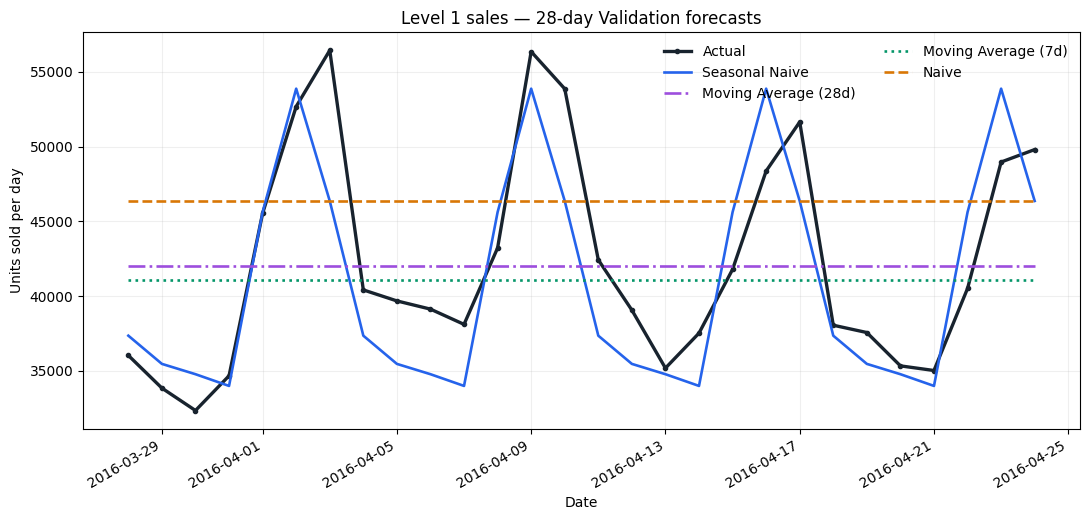

In [8]:
validation_predictions = predictions[
    (predictions['fold'] == len(ORIGINS))
].copy()

fig, ax = plt.subplots(figsize=(11, 5.3))
actual_frame = frames['val']
ax.plot(pd.to_datetime(actual_frame['date']), actual_frame['total_sales'],
        color='#18232e', linewidth=2.4, marker='o', markersize=3, label='Actual')
colors = {'naive': '#d97706', 'seasonal_naive_7': '#2563eb',
          'moving_average_7': '#059669', 'moving_average_28': '#9d4edd'}
styles = {'naive': '--', 'seasonal_naive_7': '-',
          'moving_average_7': ':', 'moving_average_28': '-.'}
for row in baseline_summary.itertuples(index=False):
    subset = validation_predictions[validation_predictions['config_id'] == row.config_id]
    label = row.model if row.model != 'Moving Average' else f'Moving Average ({int(row.window)}d)'
    ax.plot(pd.to_datetime(subset['date']), subset['prediction'], label=label,
            color=colors[row.config_id], linestyle=styles[row.config_id], linewidth=1.9)
ax.set(title='Level 1 sales — 28-day Validation forecasts',
       xlabel='Date', ylabel='Units sold per day')
ax.grid(alpha=0.2)
ax.legend(frameon=False, ncol=2)
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
plt.show()
plt.close(fig)

## 6. Save results and one download bundle

The ZIP contains the fold scores, four-configuration summary, daily forecasts,
Validation figure, and a run report. Predictions are development forecasts,
not forecasts for the independent Test period. The folder paths match the
project structure for later handoff.

In [9]:
table_dir = output_dir / '04_Outputs_and_Artifacts' / 'table'
figure_dir = output_dir / '04_Outputs_and_Artifacts' / 'figures'
prediction_dir = output_dir / '02_Data' / 'predictions'
for directory in [table_dir, figure_dir, prediction_dir]:
    directory.mkdir(parents=True, exist_ok=True)

scores_path = table_dir / 'baseline_cv_scores.csv'
summary_path = table_dir / 'baseline_summary.csv'
prediction_path = prediction_dir / 'baseline_cv_predictions.csv'
figure_path = figure_dir / 'baseline_validation_forecasts.png'
report_path = output_dir / '04_Outputs_and_Artifacts' / 'baseline_run_report.json'
cv_scores.to_csv(scores_path, index=False, float_format='%.12g')
baseline_summary.to_csv(summary_path, index=False, float_format='%.12g')
predictions.to_csv(prediction_path, index=False, float_format='%.12g')
fig.savefig(figure_path, dpi=300, bbox_inches='tight')

versions = {}
for package in ['numpy', 'pandas', 'matplotlib']:
    versions[package] = metadata.version(package)
report = {
    'status': 'PASS',
    'checked_at_utc': datetime.now(timezone.utc).isoformat(),
    'python': platform.python_version(),
    'random_seed': SEED,
    'packages': versions,
    'data_directory': str(data_dir),
    'files_read': list(FILENAMES),
    'test_labels_read': False,
    'test_forecasts_computed': False,
    'forecast_horizon': HORIZON,
    'origins': list(ORIGINS),
    'fold_plan': fold_plan.to_dict(orient='records'),
    'candidates': CONFIGS,
    'ranking_rule': 'Validation RMSSE ascending; retain all four configurations',
    'rmsse_scale_rule': 'mean squared first differences of the observed prefix in each fold',
    'metrics': {
        'mae': 'mean(abs(actual - prediction))',
        'rmse': 'sqrt(mean((actual - prediction)**2))',
        'rmsse': 'sqrt(mean((actual - prediction)**2) / rmsse_scale)',
    },
    'data_fingerprints': {item['file']: item['table_sha256'] for item in input_inventory},
    'original_train_rmsse_scale': float(np.mean(np.diff(
        frames['train']['total_sales'].to_numpy(dtype=np.float64)) ** 2)),
    'baseline_summary': baseline_summary.to_dict(orient='records'),
    'candidate_fold_scores': cv_scores.to_dict(orient='records'),
    'forecast_records': len(predictions),
    'clipped_forecasts': int(cv_scores['clipped_count'].sum()),
    'clipped_fraction': float(cv_scores['clipped_count'].sum() / len(predictions)),
    'run_seconds_before_packaging': float(perf_counter() - RUN_STARTED),
    'limitations': [
        'Three consecutive late-history windows do not cover all annual seasons.',
        'All reported errors are development scores, not final Test estimates.',
    ],
}
report_path.write_text(json.dumps(report, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')

files_to_package = [scores_path, summary_path, prediction_path, figure_path, report_path]
archive_path = output_dir / '01_baselines_results.zip'
with ZipFile(archive_path, 'w', compression=ZIP_DEFLATED) as archive:
    for path in files_to_package:
        archive.write(path, arcname=path.relative_to(output_dir))

print('BASELINE CHECK PASSED')
print(f'Configurations: {len(CONFIGS)}; folds: {len(ORIGINS)}; forecast rows: {len(predictions)}')
print(f'Download bundle: {archive_path.resolve()}')
print(baseline_summary[['model', 'config_id', 'mean_rmsse', 'std_rmsse',
                'validation_rmsse']].round(4).to_string(index=False))

BASELINE CHECK PASSED
Configurations: 4; folds: 3; forecast rows: 336
Download bundle: /kaggle/working/01_baselines_results.zip
         model         config_id  mean_rmsse  std_rmsse  validation_rmsse
Seasonal Naive  seasonal_naive_7      0.7519     0.1542            0.6677
Moving Average moving_average_28      1.1643     0.0603            1.2001
Moving Average  moving_average_7      1.2238     0.0533            1.2165
         Naive             naive      1.7027     0.2758            1.3843


## References

Hyndman, R. J. & Athanasopoulos, G. *Forecasting: Principles and Practice*,
3rd edition, Chapter 5 (simple methods and time-series cross-validation):
https://otexts.com/fpp3/toolbox.html

The 28-day horizon, Level 1 target, data split, and first-difference RMSSE
definition follow the group's finalized IS403 project plan. The explicit
development origins above implement its three windows spaced 28 days apart.